## Imports and device setup

In [1]:
import os
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python environment ready!")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Python environment ready!
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Device: cpu


In [2]:
DATA_DIR = Path.cwd() / "Data"

TRAIN_DIR = DATA_DIR / "train"
VALID_DIR = DATA_DIR / "valid"
TEST_DIR = DATA_DIR / "test"

for folder in [TRAIN_DIR, VALID_DIR, TEST_DIR]:
    if not folder.exists():
        raise FileNotFoundError(
            f"Folder not found: {folder}\n"
            "Make sure the notebook is saved in the BTIC project root."
        )

train_raw = datasets.ImageFolder(TRAIN_DIR)
valid_raw = datasets.ImageFolder(VALID_DIR)
test_raw = datasets.ImageFolder(TEST_DIR)

CLASS_NAMES = train_raw.classes
NUM_CLASSES = len(CLASS_NAMES)

print("Dataset loaded successfully!")
print("Classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

assert train_raw.class_to_idx == valid_raw.class_to_idx, \
    "Training and validation classes do not match."

assert train_raw.class_to_idx == test_raw.class_to_idx, \
    "Training and test classes do not match."

summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Images": [
        len(train_raw),
        len(valid_raw),
        len(test_raw)
    ]
})

display(summary)

print("\nClass mapping:")
print(train_raw.class_to_idx)

Dataset loaded successfully!
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Number of classes: 4


,Dataset,Images
0,Train,1695
1,Validation,502
2,Test,246



Class mapping:
{'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


,Class,Train,Validation,Test
0,glioma,564,161,80
1,meningioma,358,124,63
2,no_tumor,335,99,49
3,pituitary,438,118,54


Total images: 2443


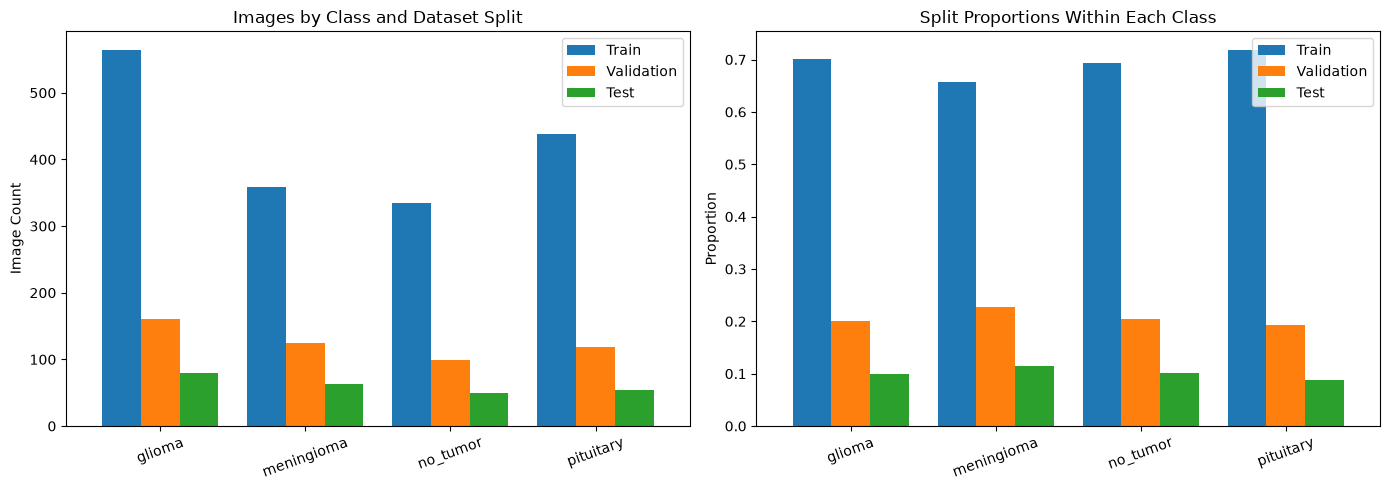

In [12]:
# Dataset summary by split and class

def get_class_counts(dataset):
    return np.bincount(
        dataset.targets,
        minlength=len(dataset.classes)
    )

distribution = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Train": get_class_counts(train_raw),
    "Validation": get_class_counts(valid_raw),
    "Test": get_class_counts(test_raw)
})

display(distribution)

print("Total images:", len(train_raw) + len(valid_raw) + len(test_raw))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

distribution.set_index("Class")[["Train", "Validation", "Test"]].plot(
    kind="bar", ax=axes[0], width=0.8
)
axes[0].set_title("Images by Class and Dataset Split")
axes[0].set_xlabel("")
axes[0].set_ylabel("Image Count")
axes[0].tick_params(axis="x", rotation=20)

distribution.set_index("Class")[["Train", "Validation", "Test"]].div(
    distribution.set_index("Class")[["Train", "Validation", "Test"]].sum(axis=1),
    axis=0
).plot(kind="bar", ax=axes[1], width=0.8)

axes[1].set_title("Split Proportions Within Each Class")
axes[1].set_xlabel("")
axes[1].set_ylabel("Proportion")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## Display sample MRI images

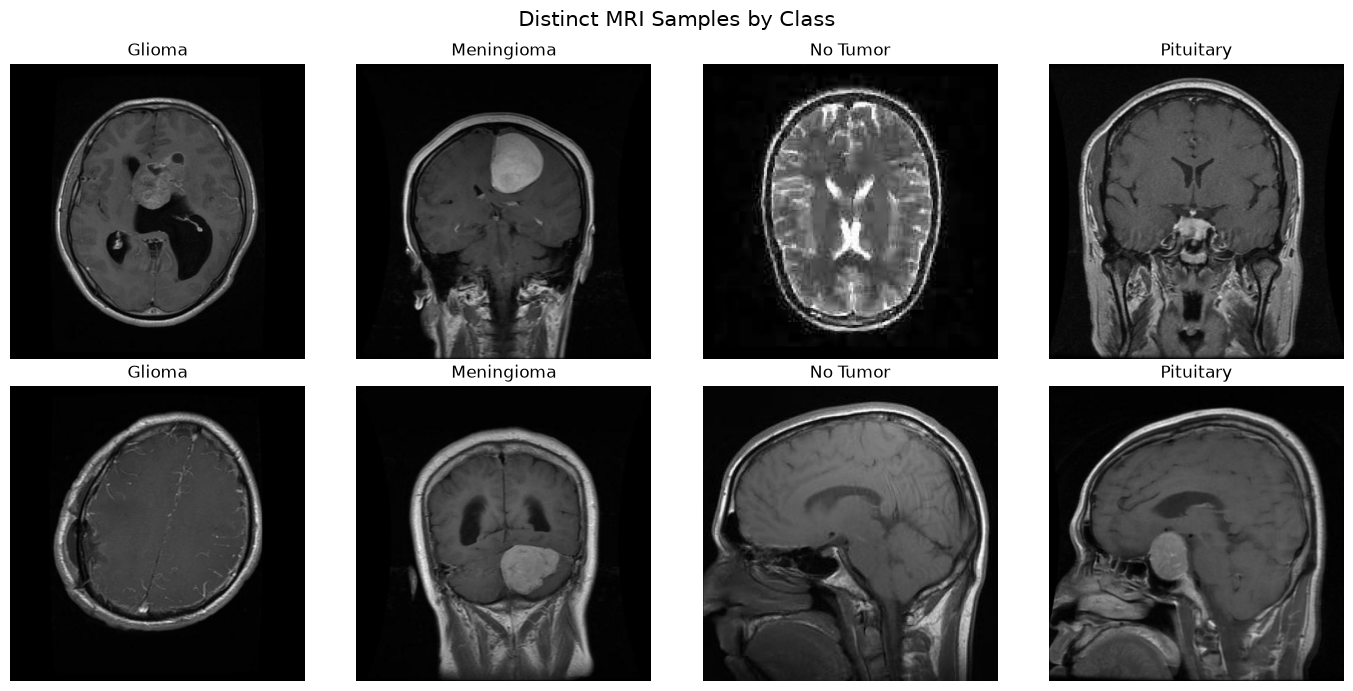

In [13]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(14, 7)
)

for class_idx, class_name in enumerate(CLASS_NAMES):
    image_paths = [
        p for p, label in train_raw.samples
        if label == class_idx
    ]

    selected = random.sample(
        image_paths,
        k=min(2, len(image_paths))
    )

    for row_idx, image_path in enumerate(selected):
        with Image.open(image_path) as img:
            axes[row_idx, class_idx].imshow(img.convert("RGB"))

        axes[row_idx, class_idx].set_title(
            class_name.replace("_", " ").title()
        )
        axes[row_idx, class_idx].axis("off")

plt.suptitle("Distinct MRI Samples by Class", fontsize=15)
plt.tight_layout()
plt.show()

In [14]:
from collections import Counter
import hashlib

all_splits = {
    "train": TRAIN_DIR,
    "valid": VALID_DIR,
    "test": TEST_DIR
}

dimension_counts = Counter()
corrupt_files = []
hash_locations = {}

for split_name, split_dir in all_splits.items():
    for image_path in split_dir.rglob("*"):
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            continue

        try:
            with Image.open(image_path) as img:
                img.verify()

            with Image.open(image_path) as img:
                dimension_counts[img.size] += 1

            digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
            hash_locations.setdefault(digest, []).append(
                (split_name, str(image_path))
            )

        except Exception as exc:
            corrupt_files.append((str(image_path), str(exc)))

print("Most common image dimensions:")
for size, count in dimension_counts.most_common(10):
    print(f"{size}: {count} images")

print("\nCorrupt/unreadable images:", len(corrupt_files))

duplicates = [
    paths for paths in hash_locations.values()
    if len(paths) > 1
]

print("Exact duplicate image groups:", len(duplicates))

cross_split_duplicates = [
    paths for paths in duplicates
    if len({item[0] for item in paths}) > 1
]

print("Duplicate groups spanning different splits:",
      len(cross_split_duplicates))

if corrupt_files:
    print("\nFirst five problematic files:")
    for item in corrupt_files[:5]:
        print(item)

if cross_split_duplicates:
    print("\nReview these cross-split duplicates:")
    for group in cross_split_duplicates[:5]:
        print(group)

Most common image dimensions:
(640, 640): 2443 images

Corrupt/unreadable images: 0
Exact duplicate image groups: 0
Duplicate groups spanning different splits: 0


## Save the dataset audit

In [15]:
OUTPUT_DIR = Path("outputs")
MODEL_DIR = Path("models")

OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

distribution.to_csv(
    OUTPUT_DIR / "dataset_distribution.csv",
    index=False
)

dimension_df = pd.DataFrame(
    [
        {"Width": width, "Height": height, "Count": count}
        for (width, height), count in dimension_counts.items()
    ]
)

dimension_df.to_csv(
    OUTPUT_DIR / "image_dimensions.csv",
    index=False
)

with open(OUTPUT_DIR / "data_quality_report.txt", "w", encoding="utf-8") as f:
    f.write(f"Train images: {len(train_raw)}\n")
    f.write(f"Validation images: {len(valid_raw)}\n")
    f.write(f"Test images: {len(test_raw)}\n")
    f.write(f"Corrupt/unreadable images: {len(corrupt_files)}\n")
    f.write(f"Exact duplicate groups: {len(duplicates)}\n")
    f.write(f"Cross-split duplicate groups: {len(cross_split_duplicates)}\n")
    f.write(f"Class names: {CLASS_NAMES}\n")
    f.write(f"Class mapping: {train_raw.class_to_idx}\n")

print("Dataset audit saved in outputs/")

Dataset audit saved in outputs/


## Part 2 - Improve preprocessing and augmentation

In [16]:
IMAGE_SIZE = 160
BATCH_SIZE = 32

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=8),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.08, contrast=0.08),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

train_dataset = datasets.ImageFolder(
    TRAIN_DIR, transform=train_transform
)
valid_dataset = datasets.ImageFolder(
    VALID_DIR, transform=eval_transform
)
test_dataset = datasets.ImageFolder(
    TEST_DIR, transform=eval_transform
)

assert train_dataset.class_to_idx == valid_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

CLASS_NAMES = train_dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)
valid_loader = DataLoader(
    valid_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Classes:", CLASS_NAMES)
print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Test batches:", len(test_loader))
print("Device:", DEVICE)

Image size: 160
Batch size: 32
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Training batches: 53
Validation batches: 16
Test batches: 8
Device: cpu


# Train the custom CNN
## Define the CNN and loss function

In [17]:
class BrainTumorCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


train_counts = get_class_counts(train_raw).astype(np.float32)

class_weights = train_counts.sum() / (
    NUM_CLASSES * train_counts
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

print("Class weights:")
for name, weight in zip(CLASS_NAMES, class_weights):
    print(f"{name}: {weight:.3f}")

cnn_model = BrainTumorCNN(NUM_CLASSES).to(DEVICE)

print("\nTrainable parameters:",
      sum(p.numel() for p in cnn_model.parameters()
          if p.requires_grad))

Class weights:
glioma: 0.751
meningioma: 1.184
no_tumor: 1.265
pituitary: 0.967

Trainable parameters: 390404


# Part 4 — Training with checkpoints and early stopping
## Define reusable training functions

In [18]:
from sklearn.metrics import f1_score, precision_score, recall_score

def predict_loader(model, loader):
    model.eval()
    y_true, y_pred, probabilities = [], [], []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            logits = model(x)
            probs = torch.softmax(logits, dim=1)

            y_true.extend(y.numpy().tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
            probabilities.extend(probs.cpu().numpy().tolist())

    return (
        np.asarray(y_true),
        np.asarray(y_pred),
        np.asarray(probabilities)
    )


def validation_metrics(model, loader):
    y_true, y_pred, _ = predict_loader(model, loader)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred,
            labels=list(range(NUM_CLASSES)),
            average="macro",
            zero_division=0
        )
    }


def train_model(
    model,
    optimizer,
    model_name,
    epochs=10,
    patience=3
):
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_macro_f1": [],
        "learning_rate": []
    }

    checkpoint_path = MODEL_DIR / f"{model_name}_best.pth"

    best_f1 = -1.0
    epochs_without_improvement = 0

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=1
    )

    for epoch in range(epochs):
        start_time = time.time()

        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / total
        train_accuracy = correct / total

        model.eval()
        val_loss_sum = 0.0
        val_total = 0

        with torch.no_grad():
            for x, y in valid_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                logits = model(x)
                loss = criterion(logits, y)
                val_loss_sum += loss.item() * y.size(0)
                val_total += y.size(0)

        val_loss = val_loss_sum / val_total
        val_metrics = validation_metrics(model, valid_loader)
        val_accuracy = val_metrics["accuracy"]
        val_f1 = val_metrics["macro_f1"]

        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["val_macro_f1"].append(val_f1)
        history["learning_rate"].append(current_lr)

        scheduler.step(val_f1)

        if val_f1 > best_f1:
            best_f1 = val_f1
            epochs_without_improvement = 0

            torch.save(model.state_dict(), checkpoint_path)
            improved = " * saved best"
        else:
            epochs_without_improvement += 1
            improved = ""

        print(
            f"{model_name} | Epoch {epoch + 1}/{epochs} | "
            f"Train Acc {train_accuracy:.3f} | "
            f"Val Acc {val_accuracy:.3f} | "
            f"Val Macro-F1 {val_f1:.3f} | "
            f"Val Loss {val_loss:.3f} | "
            f"Time {time.time() - start_time:.1f}s"
            f"{improved}"
        )

        if epochs_without_improvement >= patience:
            print("Early stopping: validation macro F1 did not improve.")
            break

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=True
        )
    )

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        OUTPUT_DIR / f"{model_name}_training_history.csv",
        index=False
    )

    return model, history

## Train the custom CNN


In [19]:
cnn_model = BrainTumorCNN(NUM_CLASSES).to(DEVICE)

cnn_optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

cnn_model, cnn_history = train_model(
    cnn_model,
    cnn_optimizer,
    model_name="custom_cnn",
    epochs=10,
    patience=3
)

custom_cnn | Epoch 1/10 | Train Acc 0.701 | Val Acc 0.538 | Val Macro-F1 0.490 | Val Loss 1.031 | Time 48.2s * saved best
custom_cnn | Epoch 2/10 | Train Acc 0.745 | Val Acc 0.769 | Val Macro-F1 0.762 | Val Loss 0.581 | Time 47.5s * saved best
custom_cnn | Epoch 3/10 | Train Acc 0.758 | Val Acc 0.404 | Val Macro-F1 0.365 | Val Loss 1.466 | Time 46.7s
custom_cnn | Epoch 4/10 | Train Acc 0.778 | Val Acc 0.422 | Val Macro-F1 0.316 | Val Loss 1.708 | Time 46.4s
custom_cnn | Epoch 5/10 | Train Acc 0.799 | Val Acc 0.767 | Val Macro-F1 0.762 | Val Loss 0.569 | Time 46.6s * saved best
custom_cnn | Epoch 6/10 | Train Acc 0.811 | Val Acc 0.787 | Val Macro-F1 0.772 | Val Loss 0.572 | Time 47.1s * saved best
custom_cnn | Epoch 7/10 | Train Acc 0.802 | Val Acc 0.629 | Val Macro-F1 0.610 | Val Loss 0.944 | Time 45.5s
custom_cnn | Epoch 8/10 | Train Acc 0.823 | Val Acc 0.723 | Val Macro-F1 0.728 | Val Loss 0.702 | Time 45.7s
custom_cnn | Epoch 9/10 | Train Acc 0.817 | Val Acc 0.833 | Val Macro-F1 0.8

# Part 5 — Transfer learning and fine-tuning
## Train MobileNetV3 with pretrained weights

In [20]:
weights = models.MobileNet_V3_Small_Weights.DEFAULT

mobilenet_model = models.mobilenet_v3_small(weights=weights)

for param in mobilenet_model.features.parameters():
    param.requires_grad = False

in_features = mobilenet_model.classifier[3].in_features

mobilenet_model.classifier[3] = nn.Linear(
    in_features, NUM_CLASSES
)

mobilenet_model = mobilenet_model.to(DEVICE)

head_optimizer = optim.Adam(
    mobilenet_model.classifier.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

mobilenet_model, mobilenet_history = train_model(
    mobilenet_model,
    head_optimizer,
    model_name="mobilenet_v3_head",
    epochs=8,
    patience=3
)

mobilenet_v3_head | Epoch 1/8 | Train Acc 0.757 | Val Acc 0.669 | Val Macro-F1 0.679 | Val Loss 0.782 | Time 16.6s * saved best
mobilenet_v3_head | Epoch 2/8 | Train Acc 0.832 | Val Acc 0.679 | Val Macro-F1 0.647 | Val Loss 0.972 | Time 16.8s
mobilenet_v3_head | Epoch 3/8 | Train Acc 0.857 | Val Acc 0.835 | Val Macro-F1 0.831 | Val Loss 0.469 | Time 15.3s * saved best
mobilenet_v3_head | Epoch 4/8 | Train Acc 0.872 | Val Acc 0.821 | Val Macro-F1 0.818 | Val Loss 0.507 | Time 15.6s
mobilenet_v3_head | Epoch 5/8 | Train Acc 0.884 | Val Acc 0.805 | Val Macro-F1 0.798 | Val Loss 0.481 | Time 16.0s
mobilenet_v3_head | Epoch 6/8 | Train Acc 0.910 | Val Acc 0.807 | Val Macro-F1 0.795 | Val Loss 0.546 | Time 16.4s
Early stopping: validation macro F1 did not improve.


# Fine-tune the final feature layers

In [21]:
# Unfreeze the last three feature blocks.
for param in mobilenet_model.features[-3:].parameters():
    param.requires_grad = True

fine_tune_optimizer = optim.Adam(
    [
        {
            "params": [
                p for p in mobilenet_model.features.parameters()
                if p.requires_grad
            ],
            "lr": 1e-4
        },
        {
            "params": mobilenet_model.classifier.parameters(),
            "lr": 2e-4
        }
    ],
    weight_decay=1e-4
)

mobilenet_model, finetune_history = train_model(
    mobilenet_model,
    fine_tune_optimizer,
    model_name="mobilenet_v3_finetuned",
    epochs=6,
    patience=2
)

mobilenet_v3_finetuned | Epoch 1/6 | Train Acc 0.893 | Val Acc 0.803 | Val Macro-F1 0.795 | Val Loss 0.511 | Time 17.0s * saved best
mobilenet_v3_finetuned | Epoch 2/6 | Train Acc 0.916 | Val Acc 0.753 | Val Macro-F1 0.730 | Val Loss 0.729 | Time 18.0s
mobilenet_v3_finetuned | Epoch 3/6 | Train Acc 0.919 | Val Acc 0.823 | Val Macro-F1 0.809 | Val Loss 0.491 | Time 17.4s * saved best
mobilenet_v3_finetuned | Epoch 4/6 | Train Acc 0.945 | Val Acc 0.825 | Val Macro-F1 0.814 | Val Loss 0.495 | Time 17.7s * saved best
mobilenet_v3_finetuned | Epoch 5/6 | Train Acc 0.937 | Val Acc 0.853 | Val Macro-F1 0.846 | Val Loss 0.433 | Time 17.8s * saved best
mobilenet_v3_finetuned | Epoch 6/6 | Train Acc 0.948 | Val Acc 0.855 | Val Macro-F1 0.850 | Val Loss 0.435 | Time 17.8s * saved best


# Part 6 — Learning curves and model evaluation
## Visualize training history

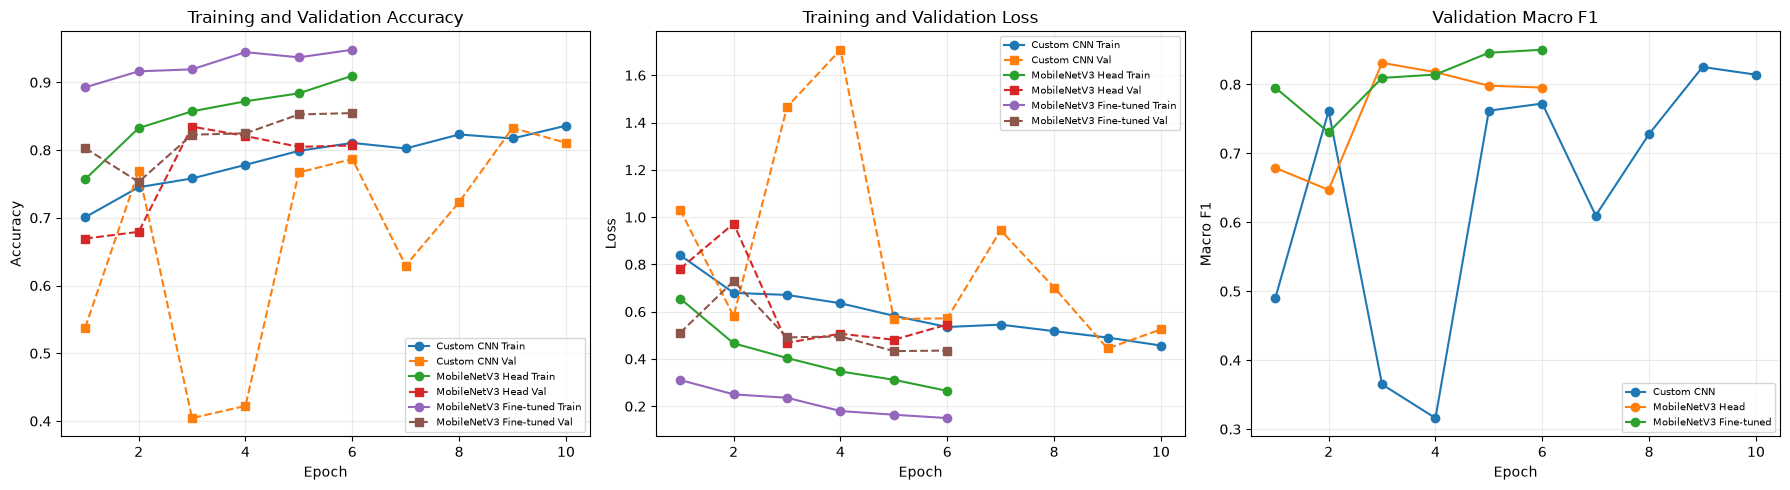

In [22]:
histories = {
    "Custom CNN": cnn_history,
    "MobileNetV3 Head": mobilenet_history,
    "MobileNetV3 Fine-tuned": finetune_history
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for name, history in histories.items():
    epochs = range(1, len(history["train_accuracy"]) + 1)

    axes[0].plot(epochs, history["train_accuracy"], marker="o",
                 label=f"{name} Train")
    axes[0].plot(epochs, history["val_accuracy"], marker="s",
                 linestyle="--", label=f"{name} Val")

    axes[1].plot(epochs, history["train_loss"], marker="o",
                 label=f"{name} Train")
    axes[1].plot(epochs, history["val_loss"], marker="s",
                 linestyle="--", label=f"{name} Val")

    axes[2].plot(epochs, history["val_macro_f1"], marker="o",
                 label=name)

axes[0].set_title("Training and Validation Accuracy")
axes[0].set_ylabel("Accuracy")

axes[1].set_title("Training and Validation Loss")
axes[1].set_ylabel("Loss")

axes[2].set_title("Validation Macro F1")
axes[2].set_ylabel("Macro F1")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=180)
plt.show()

## Select the best candidate using validation data

In [23]:
# Reconstruct the head-only MobileNet model from its checkpoint.
mobilenet_head_model = models.mobilenet_v3_small(weights=None)

mobilenet_head_model.classifier[3] = nn.Linear(
    mobilenet_head_model.classifier[3].in_features,
    NUM_CLASSES
)

mobilenet_head_model.load_state_dict(
    torch.load(
        MODEL_DIR / "mobilenet_v3_head_best.pth",
        map_location=DEVICE,
        weights_only=True
    )
)

mobilenet_head_model = mobilenet_head_model.to(DEVICE)

candidate_models = {
    "Custom CNN": cnn_model,
    "MobileNetV3 Head": mobilenet_head_model,
    "MobileNetV3 Fine-tuned": mobilenet_model
}

validation_rows = []

for name, model in candidate_models.items():
    y_true, y_pred, _ = predict_loader(model, valid_loader)

    validation_rows.append({
        "Model": name,
        "Validation Accuracy": accuracy_score(y_true, y_pred),
        "Validation Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Validation Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Validation Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    })

validation_comparison = pd.DataFrame(validation_rows).sort_values(
    "Validation Macro F1", ascending=False
)

display(validation_comparison)

validation_comparison.to_csv(
    OUTPUT_DIR / "validation_model_comparison.csv",
    index=False
)

best_model_name = validation_comparison.iloc[0]["Model"]
best_model = candidate_models[best_model_name]

print("Selected using validation macro F1:", best_model_name)

,Model,Validation Accuracy,Validation Macro Precision,Validation Macro Recall,Validation Macro F1
2,MobileNetV3 Fine-tuned,0.854582,0.856219,0.859788,0.850217
1,MobileNetV3 Head,0.834661,0.831440,0.836537,0.831259
0,Custom CNN,0.832669,0.828477,0.829411,0.825219


Selected using validation macro F1: MobileNetV3 Fine-tuned


## Final test evaluation

In [24]:
from sklearn.metrics import f1_score, precision_score, recall_score

test_rows = []
test_predictions = {}

for name, model in candidate_models.items():
    start = time.perf_counter()
    y_true, y_pred, probabilities = predict_loader(model, test_loader)
    elapsed = time.perf_counter() - start

    test_predictions[name] = (y_true, y_pred, probabilities)

    test_rows.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Inference Seconds": elapsed
    })

test_comparison = pd.DataFrame(test_rows).sort_values(
    "Test Accuracy", ascending=False
)

display(test_comparison)

test_comparison.to_csv(
    OUTPUT_DIR / "test_model_comparison.csv",
    index=False
)

print("\nFinal selected model:", best_model_name)

selected_true, selected_pred, selected_probabilities = (
    test_predictions[best_model_name]
)

print("\nClassification report for selected model:\n")

print(classification_report(
    selected_true,
    selected_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Inference Seconds
0,Custom CNN,0.849593,0.844463,0.848103,0.844122,0.849459,2.651584
2,MobileNetV3 Fine-tuned,0.849593,0.856563,0.856498,0.846460,0.851887,1.380440
1,MobileNetV3 Head,0.829268,0.825795,0.833081,0.823492,0.824713,1.472789



Final selected model: MobileNetV3 Fine-tuned

Classification report for selected model:

              precision    recall  f1-score   support

      glioma     0.9718    0.8625    0.9139        80
  meningioma     0.8364    0.7302    0.7797        63
    no_tumor     0.6806    1.0000    0.8099        49
   pituitary     0.9375    0.8333    0.8824        54

    accuracy                         0.8496       246
   macro avg     0.8566    0.8565    0.8465       246
weighted avg     0.8716    0.8496    0.8519       246



## Confusion matrices for all candidates

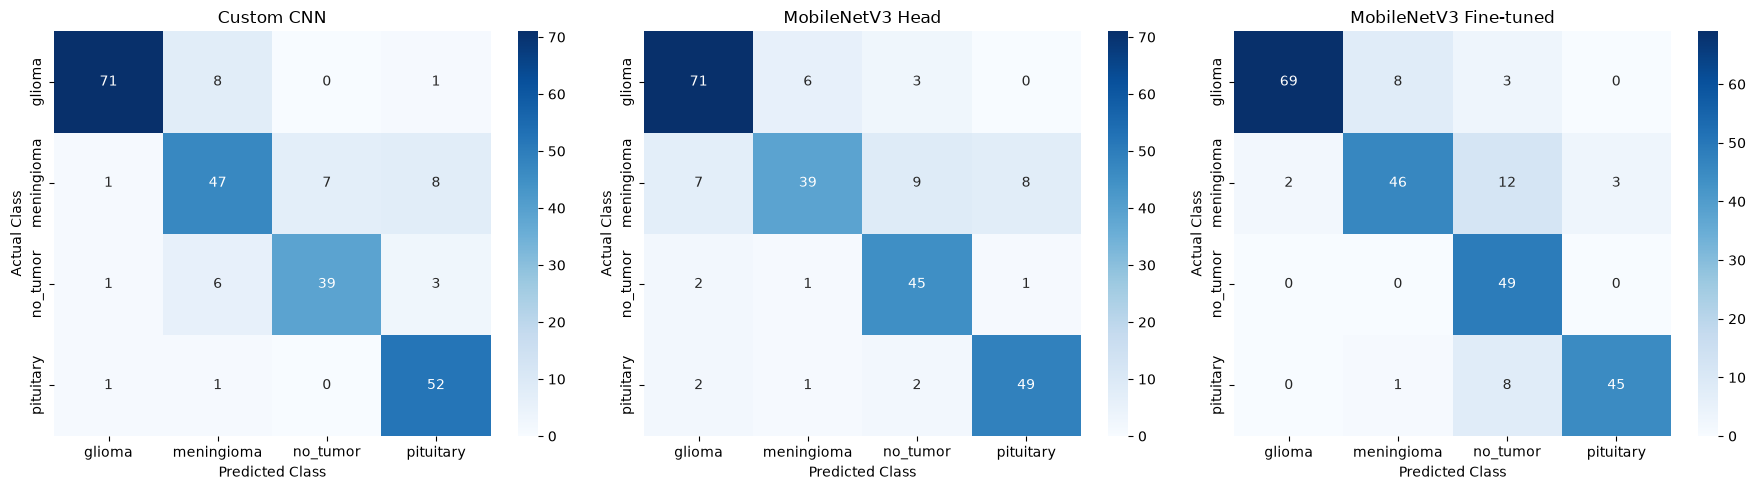

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, (y_true, y_pred, _)) in zip(
    axes, test_predictions.items()
):
    cm = confusion_matrix(
        y_true, y_pred,
        labels=list(range(NUM_CLASSES))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=180)
plt.show()

# Part 7 — Save models and reproducible training artifacts
## Save all model checkpoints with metadata

In [34]:
import json
import platform

ARTIFACTS = {
    "Custom CNN": {
        "filename": "custom_cnn_final.pth",
        "architecture": "BrainTumorCNN",
        "model": cnn_model
    },
    "MobileNetV3 Head": {
        "filename": "mobilenet_v3_head_final.pth",
        "architecture": "mobilenet_v3_small",
        "model": mobilenet_head_model
    },
    "MobileNetV3 Fine-tuned": {
        "filename": "mobilenet_v3_finetuned_final.pth",
        "architecture": "mobilenet_v3_small",
        "model": mobilenet_model
    }
}

for name, item in ARTIFACTS.items():
    artifact = {
        "architecture": item["architecture"],
        "model_state_dict": item["model"].state_dict(),
        "class_names": CLASS_NAMES,
        "class_to_idx": train_dataset.class_to_idx,
        "num_classes": NUM_CLASSES,
        "image_size": IMAGE_SIZE,
        "normalization_mean": list(IMAGENET_MEAN),
        "normalization_std": list(IMAGENET_STD),
        "selected_model": name == best_model_name,
        "pytorch_version": str(torch.__version__),
        "python_version": str(platform.python_version())
    }

    torch.save(
        artifact,
        MODEL_DIR / item["filename"]
    )

    print("Saved:", MODEL_DIR / item["filename"])

Saved: models\custom_cnn_final.pth
Saved: models\mobilenet_v3_head_final.pth
Saved: models\mobilenet_v3_finetuned_final.pth


## Save detailed per-class metrics

In [27]:
all_reports = []

for model_name, (y_true, y_pred, _) in test_predictions.items():
    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    for class_name in CLASS_NAMES:
        row = report[class_name].copy()
        row["Class"] = class_name
        row["Model"] = model_name
        all_reports.append(row)

per_class_metrics = pd.DataFrame(all_reports)

per_class_metrics.to_csv(
    OUTPUT_DIR / "per_class_test_metrics.csv",
    index=False
)

display(per_class_metrics)

,precision,recall,f1-score,support,Class,Model
0,0.959459,0.887500,0.922078,80.0,glioma,Custom CNN
1,0.758065,0.746032,0.752000,63.0,meningioma,Custom CNN
2,0.847826,0.795918,0.821053,49.0,no_tumor,Custom CNN
3,0.812500,0.962963,0.881356,54.0,pituitary,Custom CNN
4,0.865854,0.887500,0.876543,80.0,glioma,MobileNetV3 Head
5,0.829787,0.619048,0.709091,63.0,meningioma,MobileNetV3 Head
6,0.762712,0.918367,0.833333,49.0,no_tumor,MobileNetV3 Head
7,0.844828,0.907407,0.875000,54.0,pituitary,MobileNetV3 Head
8,0.971831,0.862500,0.913907,80.0,glioma,MobileNetV3 Fine-tuned
9,0.836364,0.730159,0.779661,63.0,meningioma,MobileNetV3 Fine-tuned


## Create a project configuration file

In [33]:
project_config = {
    "project_name": "Brain Tumor MRI Image Classification",
    "framework": "PyTorch",
    "pytorch_version": str(torch.__version__),
    "python_version": str(platform.python_version()),
    "device": str(DEVICE),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "classes": CLASS_NAMES,
    "class_to_idx": train_dataset.class_to_idx,
    "selected_model": best_model_name,
    "selection_metric": "Validation Macro F1",
    "models_trained": list(candidate_models.keys())
}

with open(
    OUTPUT_DIR / "project_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(project_config, f, indent=4)

print(json.dumps(project_config, indent=4))

{
    "project_name": "Brain Tumor MRI Image Classification",
    "framework": "PyTorch",
    "pytorch_version": "2.14.1+cpu",
    "python_version": "3.14.6",
    "device": "cpu",
    "image_size": 160,
    "batch_size": 32,
    "classes": [
        "glioma",
        "meningioma",
        "no_tumor",
        "pituitary"
    ],
    "class_to_idx": {
        "glioma": 0,
        "meningioma": 1,
        "no_tumor": 2,
        "pituitary": 3
    },
    "selected_model": "MobileNetV3 Fine-tuned",
    "selection_metric": "Validation Macro F1",
    "models_trained": [
        "Custom CNN",
        "MobileNetV3 Head",
        "MobileNetV3 Fine-tuned"
    ]
}


## Verify the saved artifacts

In [29]:
print("MODEL ARTIFACTS")
print("=" * 50)

for name, item in ARTIFACTS.items():
    path = MODEL_DIR / item["filename"]

    if not path.exists():
        print("MISSING:", path)
        continue

    print(f"{name}: {path.stat().st_size / (1024**2):.2f} MB")

print("\nOUTPUT FILES")
print("=" * 50)

for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name, f"({path.stat().st_size / 1024:.1f} KB)")

print("\nSaved artifacts verified.")

MODEL ARTIFACTS
Custom CNN: 1.50 MB
MobileNetV3 Head: 5.93 MB
MobileNetV3 Fine-tuned: 5.94 MB

OUTPUT FILES
confusion_matrices.png (145.4 KB)
custom_cnn_training_history.csv (1.1 KB)
data_quality_report.txt (0.3 KB)
dataset_distribution.csv (0.1 KB)
image_dimensions.csv (0.0 KB)
mobilenet_v3_finetuned_training_history.csv (0.7 KB)
mobilenet_v3_head_training_history.csv (0.7 KB)
model_comparison.csv (0.1 KB)
per_class_test_metrics.csv (1.0 KB)
project_config.json (0.7 KB)
test_model_comparison.csv (0.5 KB)
training_curves.png (270.0 KB)
validation_model_comparison.csv (0.4 KB)

Saved artifacts verified.


# Part 8 — Final notebook verification
## Confirm that the notebook outputs are ready

In [30]:
required_outputs = [
    "dataset_distribution.csv",
    "image_dimensions.csv",
    "data_quality_report.txt",
    "custom_cnn_training_history.csv",
    "mobilenet_v3_head_training_history.csv",
    "mobilenet_v3_finetuned_training_history.csv",
    "validation_model_comparison.csv",
    "test_model_comparison.csv",
    "per_class_test_metrics.csv",
    "project_config.json",
    "training_curves.png",
    "confusion_matrices.png"
]

print("Notebook completion audit")
print("=" * 45)

missing = []

for filename in required_outputs:
    path = OUTPUT_DIR / filename
    status = "OK" if path.exists() else "MISSING"
    print(f"{status:8} {filename}")

    if not path.exists():
        missing.append(filename)

for filename in [
    "custom_cnn_final.pth",
    "mobilenet_v3_head_final.pth",
    "mobilenet_v3_finetuned_final.pth"
]:
    path = MODEL_DIR / filename
    status = "OK" if path.exists() else "MISSING"
    print(f"{status:8} models/{filename}")

    if not path.exists():
        missing.append(f"models/{filename}")

if missing:
    print("\nSome artifacts are missing. Check the corresponding cells.")
else:
    print("\nAll required notebook artifacts have been generated.")

Notebook completion audit
OK       dataset_distribution.csv
OK       image_dimensions.csv
OK       data_quality_report.txt
OK       custom_cnn_training_history.csv
OK       mobilenet_v3_head_training_history.csv
OK       mobilenet_v3_finetuned_training_history.csv
OK       validation_model_comparison.csv
OK       test_model_comparison.csv
OK       per_class_test_metrics.csv
OK       project_config.json
OK       training_curves.png
OK       confusion_matrices.png
OK       models/custom_cnn_final.pth
OK       models/mobilenet_v3_head_final.pth
OK       models/mobilenet_v3_finetuned_final.pth

All required notebook artifacts have been generated.


In [32]:

# Verify that the saved selected-model artifact can be loaded
# and produces valid predictions.

selected_artifact_path = (
    MODEL_DIR / ARTIFACTS[best_model_name]["filename"]
)

# Allowlist the specific PyTorch version class stored in our artifact.
from torch.torch_version import TorchVersion

with torch.serialization.safe_globals([TorchVersion]):
    artifact = torch.load(
        selected_artifact_path,
        map_location=DEVICE,
        weights_only=True
    )

assert artifact["class_names"] == CLASS_NAMES
assert artifact["num_classes"] == NUM_CLASSES

if artifact["architecture"] == "BrainTumorCNN":
    reloaded_model = BrainTumorCNN(NUM_CLASSES)
else:
    reloaded_model = models.mobilenet_v3_small(weights=None)
    reloaded_model.classifier[3] = nn.Linear(
        reloaded_model.classifier[3].in_features,
        NUM_CLASSES
    )

reloaded_model.load_state_dict(artifact["model_state_dict"])
reloaded_model = reloaded_model.to(DEVICE)
reloaded_model.eval()

sample_images, _ = next(iter(test_loader))

with torch.no_grad():
    logits = reloaded_model(sample_images[:2].to(DEVICE))

assert logits.shape == (2, NUM_CLASSES)
assert torch.isfinite(logits).all()

print("PASS: selected model loads and produces valid predictions.")
print("Model:", best_model_name)
print("Output shape:", tuple(logits.shape))
print("Predicted classes:", logits[:2].argmax(dim=1).cpu().tolist())


PASS: selected model loads and produces valid predictions.
Model: MobileNetV3 Fine-tuned
Output shape: (2, 4)
Predicted classes: [1, 0]
